# Medical Insurance Price Prediction

### Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### Load Dataset

In [35]:
df = pd.read_csv("Medical_insurance.csv")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Shape: (2772, 7)

Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


### Train Test Split

In [37]:
y = df["charges"]

# Single feature
x_single = df[["bmi"]]

# Multiple features
x_multi = df[
    ["age", "sex", "bmi", "children", "smoker", "region"]
]

x_single_train, x_single_test, y_train, y_test = train_test_split(
    x_single,
    y,
    test_size=0.2,
    random_state=42
)

x_multi_train, x_multi_test, _, _ = train_test_split(
    x_multi,
    y,
    test_size=0.2,
    random_state=42
)

### Preprocess Data

1. Single Feature (Normalize)

In [17]:
# Normalize
single_scaler = StandardScaler()

x_single_train_processed = single_scaler.fit_transform(x_single_train)
x_single_test_processed = single_scaler.transform(x_single_test)

print("Training shape (Single):", x_single_train_processed.shape)
print("Testing shape (Single):", x_single_test_processed.shape)

Training shape (Single): (2217, 1)
Testing shape (Single): (555, 1)


2. Multiple Features (Normalize + Encode)

In [18]:
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Preprocessing (Normalize + Encode)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

x_multi_train_processed = preprocessor.fit_transform(x_multi_train)
x_multi_test_processed = preprocessor.transform(x_multi_test)

print("Training shape (Multiple):", x_multi_train_processed.shape)
print("Testing shape: (Multiple)", x_multi_test_processed.shape)

Training shape (Multiple): (2217, 11)
Testing shape: (Multiple) (555, 11)


### Train

1. Linear Regression (Single Feature)

In [ ]:
lr_single = LinearRegression()

lr_single.fit(x_single_train_processed, y_train)

lr_single_predictions = lr_single.predict(x_single_test_processed)

2. Linear Regression (Multiple Features)

In [21]:
lr_multi = LinearRegression()

lr_multi.fit(x_multi_train_processed, y_train)

lr_multi_predictions = lr_multi.predict(x_multi_test_processed)

3. DNN (Single Feature)

In [22]:
dnn_single = Sequential([
    Dense(64, activation="relu", input_shape=(1,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

dnn_single.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history_single = dnn_single.fit(
    x_single_train_processed,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

dnn_single_predictions = dnn_single.predict(
    x_single_test_processed,
    verbose=0
).flatten()

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4. DNN (Multiple Features)

In [26]:
dnn_multi = Sequential([
    Dense(
        64,
        activation="relu",
        input_shape=(x_multi_train_processed.shape[1],)
    ),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

dnn_multi.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history_multi = dnn_multi.fit(
    x_multi_train_processed,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

dnn_multi_predictions = dnn_multi.predict(
    x_multi_test_processed,
    verbose=0
).flatten()

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Evaluate

1. Evaluate Function

In [27]:
def evaluate_model(name, y_true, predictions):

    mae = mean_absolute_error(
        y_true,
        predictions
    )

    mse = mean_squared_error(
        y_true,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        predictions
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

2. Evaluation

In [28]:
results = []

results.append(
    evaluate_model(
        "Linear Regression - Single Feature",
        y_test,
        lr_single_predictions
    )
)

results.append(
    evaluate_model(
        "Linear Regression - Multiple Features",
        y_test,
        lr_multi_predictions
    )
)

results.append(
    evaluate_model(
        "DNN - Single Feature",
        y_test,
        dnn_single_predictions
    )
)

results.append(
    evaluate_model(
        "DNN - Multiple Features",
        y_test,
        dnn_multi_predictions
    )
)

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,RMSE,R²
0,Linear Regression - Single Feature,9212.213638,12082.591035,0.048814
1,Linear Regression - Multiple Features,4160.247975,6319.271679,0.739817
2,DNN - Single Feature,9236.369287,12094.717550,0.046903
3,DNN - Multiple Features,2924.797116,5104.220045,0.830252


3. Visualize Model Performance

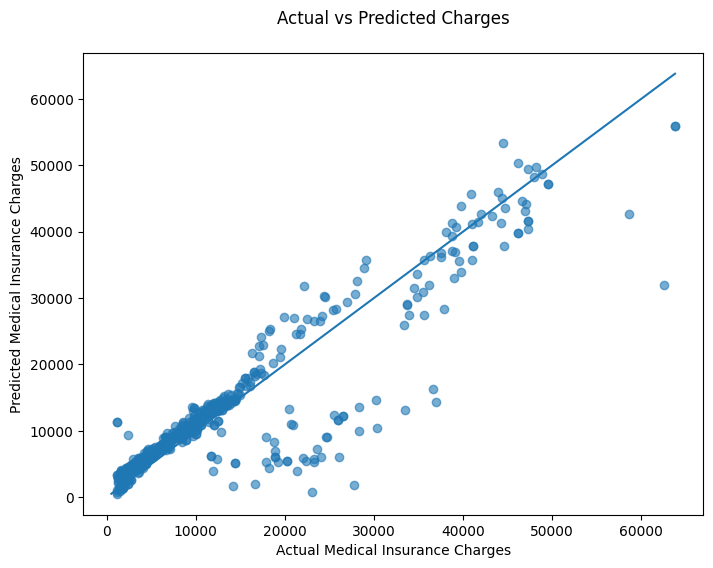

In [33]:
selected_predictions = dnn_multi_predictions



plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    selected_predictions,
    alpha=0.6
)

min_value = min(y_test.min(), selected_predictions.min())
max_value = max(y_test.max(), selected_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
)

plt.xlabel("Actual Medical Insurance Charges")
plt.ylabel("Predicted Medical Insurance Charges")
plt.title(f"Actual vs Predicted Charges\n")

plt.show()